# Deep-Sea Classification: Context Reliance & Depth Degradation
This notebook imports from the project's `.py` modules and runs the full pipeline on Colab's GPU.

# Analysis
Loads saved results from the training pipeline and runs all statistical
analyses: CRS–degradation correlation, baseline comparisons, robustness
checks, bootstrap confidence intervals, and CRS variance analysis.
No GPU required.

In [18]:
# Install any extra packages not on Colab by default
%pip install fathomnet grad-cam

In [19]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/Shareddrives/CV-Project'

import sys, os
sys.path.insert(0, PROJECT_DIR)
os.chdir(PROJECT_DIR)

import importlib
import pandas as pd
import config
import analysis
import extensions

# Load saved results
per_species_df = pd.read_csv(os.path.join(config.RESULTS_DIR, 'results.csv'), index_col='species')

# Reconstruct per-species dicts used by analysis functions
crs_scores   = per_species_df['shallow_crs'].dropna().to_dict()   # CRS on shallow test crops
degradation  = per_species_df['degradation'].dropna().to_dict()
shallow_acc  = per_species_df['shallow_acc'].dropna().to_dict()
uniform_crs  = per_species_df['uniform_crs'].dropna().to_dict()
gaussian_crs = per_species_df['gaussian_crs'].dropna().to_dict()

# Load cached predictions
int_preds = pd.read_csv(os.path.join(config.RESULTS_DIR, 'intervention_predictions.csv'))

all_ic = pd.read_csv(os.path.join(config.RESULTS_DIR, 'image_crs.csv'))
image_crs = {s: all_ic[all_ic['split'] == s].drop(columns='split') for s in ['shallow', 'deep']}

crs_cw = pd.read_csv(os.path.join(config.RESULTS_DIR, 'crs_correct_vs_incorrect.csv'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## CRS vs degradation

In [20]:
# Core hypothesis test - correlation between depth degradation and context relience

# will have to check for a minimum number of test images in deep and shallow
# currently images with 1 test shallow will be weight equally to those with hundereds
# and those with 0 will give crs_score NaN
qualifying = analysis.select_qualifying_species(per_species_df, min_test_n=5)
rho, p_value = analysis.spearman_correlation(crs_scores, degradation, species=qualifying)
print(f'Spearman ρ = {rho:.3f}, p = {p_value:.4f}')

summary = analysis.generate_summary_table(
    crs_scores, degradation, rho, p_value, species=qualifying,
    baselines={'Uniform random': uniform_crs, 'Centre Gaussian': gaussian_crs})
summary.to_csv('results/correlation_summary.csv')
summary.round(3)



139 / 314 species qualify (>= 5 shallow and deep test crops, CRS available)
Spearman over 139 species
Spearman ρ = -0.199, p = 0.0191
Spearman over 139 species
Spearman over 139 species


,n_species,mean_crs,spearman_rho,p_value
method,,,,
Grad-CAM,139,0.479,-0.199,0.019
Uniform random,139,0.748,-0.144,0.091
Centre Gaussian,139,0.565,-0.108,0.207


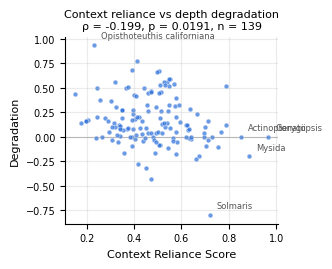

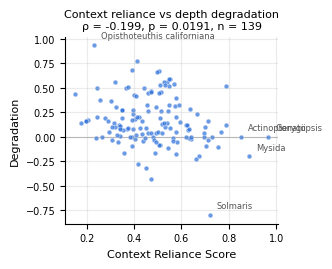

In [21]:
analysis.plot_crs_vs_degradation(crs_scores, degradation, species=qualifying, rho=rho,
                                 p_value=p_value, save_path='results/crs_vs_degradation.png')

### CRS correct vs wrong predictions


,split,n_correct,n_incorrect,median_crs_correct,median_crs_incorrect,n_empty_correct,n_empty_incorrect,p_pooled,n_species_within,median_within_species_diff,p_within
0,shallow,10741,2778,0.3758,0.5013,0,32,0.0,101,0.0977,0.0
1,deep,6403,3952,0.4338,0.5941,0,85,0.0,100,0.1297,0.0


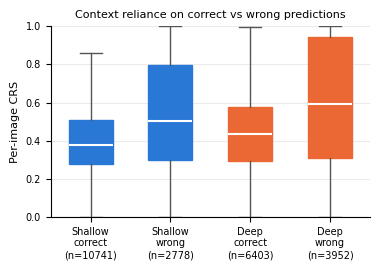

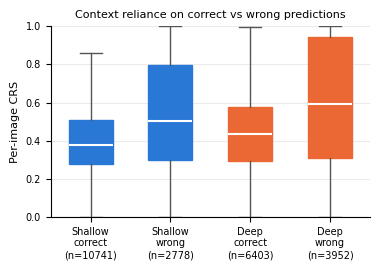

In [22]:
display(crs_cw.round(4))
extensions.plot_crs_correct_vs_incorrect(image_crs, species=qualifying,
                                         save_path='results/crs_correct_vs_wrong.png')

### Checking against baselines

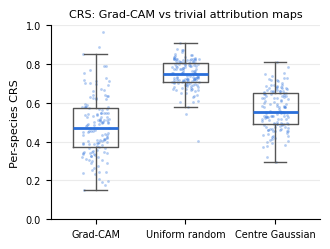

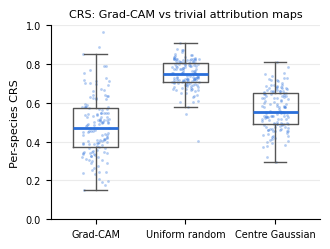

In [23]:
# Checking against baselines
# crs vs organism size (is high crs just because organism is larger in crop?)
analysis.plot_baseline_comparison(crs_scores, uniform_crs, gaussian_crs, species=qualifying,
                                  save_path='results/baseline_crs.png')


/content/drive/Shareddrives/CV-Project/analysis.py:193: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return df.groupby(bin_col)["correct"].mean()


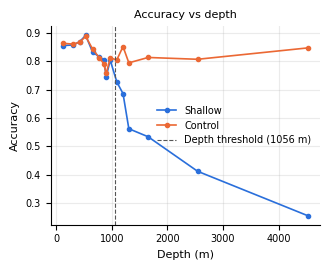

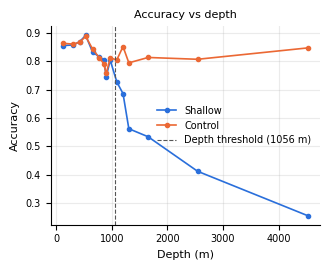

In [24]:
# degradation vs control
# Accuracy vs depth curve for shallow-trained and control models
predictions = pd.read_csv(os.path.join(config.RESULTS_DIR, 'predictions.csv'))
depth_df = pd.read_csv(config.DEPTH_PATH)

analysis.plot_accuracy_vs_depth(
    predictions, depth_df,
    depth_threshold=config.DEPTH_SHALLOW_MAX,
    save_path='results/control_comparison.png')

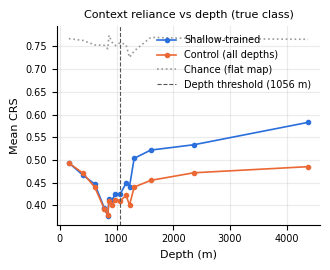

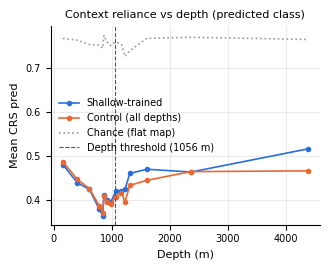

In [25]:
# Context reliance vs depth for both models, true-class and predicted-class CRS
# (the dotted chance line is the flat-map CRS: if CRS follows it, the change is mask size, not attention)
importlib.reload(analysis)
all_ic_ctrl = pd.read_csv(os.path.join(config.RESULTS_DIR, 'image_crs_control.csv'))
crs_by_model = {'shallow': all_ic, 'control': all_ic_ctrl}

for col in ['crs', 'crs_pred']:
    analysis.plot_crs_vs_depth(crs_by_model, depth_df, crs_col=col,
                               depth_threshold=config.DEPTH_SHALLOW_MAX, species=qualifying,
                               save_path=f'results/{col}_vs_depth.png')

In [26]:
# Summary table


# Attention maps, shallow-only vs control model on shallow vs deep crops: train.ipynb
# (attribution grid, needs the models) -> results/attribution_grid.png


In [27]:
# 1. Does the result depend on how many test crops a species needs?
for n in [5, 10, 20]:
    q = analysis.select_qualifying_species(per_species_df, min_test_n=n)
    r, p = analysis.spearman_correlation(crs_scores, degradation, species=q)
    print(f"min_test_n={n}: n_species={len(q)}, rho={r:.3f}, p={p:.3f}")

# 2. Species the model barely recognises even in shallow water can't degrade much,
#    which can hide a relationship. Re-run on species it learned reasonably well.
learned = [s for s in qualifying if shallow_acc[s] >= 0.3]
r, p = analysis.spearman_correlation(crs_scores, degradation, species=learned)
print(f"shallow_acc >= 0.3: n_species={len(learned)}, rho={r:.3f}, p={p:.3f}")

# 3. Species CRS from few crops is noisy: resample each species' crops for a CI on ρ
boot_rho = analysis.bootstrap_spearman(image_crs['shallow'], degradation, species=qualifying)

# 4. Median instead of mean CRS per species (less swayed by a few extreme crops)
median_crs = per_species_df['shallow_crs_median'].dropna().to_dict()
r, p = analysis.spearman_correlation(median_crs, degradation, species=qualifying)
print(f"median CRS: n_species={len(qualifying)}, rho={r:.3f}, p={p:.3f}")

# Widest per-species CRS intervals (the least certain species), from the train notebook's bootstrap
crs_bootstrap = pd.read_csv(os.path.join(config.RESULTS_DIR, 'crs_bootstrap.csv'), index_col='species')
ci_width = (crs_bootstrap['shallow_crs_ci_high'] - crs_bootstrap['shallow_crs_ci_low']).reindex(qualifying)
display(crs_bootstrap.loc[ci_width.sort_values(ascending=False).index[:10],
                          ['shallow_crs', 'shallow_crs_ci_low', 'shallow_crs_ci_high', 'shallow_n_crs']].round(3))

# 5. Predicted-class CRS: explain the species the model chose rather than the true one (differs only
#    on wrong crops, whose true-class maps are weak and diffuse). Same test, and how close the two are
pred_crs = per_species_df['shallow_crs_pred'].dropna().to_dict()
r, p = analysis.spearman_correlation(pred_crs, degradation, species=qualifying)
print(f"predicted-class CRS: n_species={len(qualifying)}, rho={r:.3f}, p={p:.3f}")
agree = per_species_df.loc[qualifying, ['shallow_crs', 'shallow_crs_pred']].dropna()
print(f"true- vs predicted-class species CRS: Spearman ρ = "
      f"{agree['shallow_crs'].corr(agree['shallow_crs_pred'], method='spearman'):.3f}, "
      f"mean difference (pred − true) = {(agree['shallow_crs_pred'] - agree['shallow_crs']).mean():.3f}")

139 / 314 species qualify (>= 5 shallow and deep test crops, CRS available)
Spearman over 139 species
min_test_n=5: n_species=139, rho=-0.199, p=0.019
98 / 314 species qualify (>= 10 shallow and deep test crops, CRS available)
Spearman over 98 species
min_test_n=10: n_species=98, rho=-0.095, p=0.351
66 / 314 species qualify (>= 20 shallow and deep test crops, CRS available)
Spearman over 66 species
min_test_n=20: n_species=66, rho=-0.170, p=0.173
Spearman over 111 species
shallow_acc >= 0.3: n_species=111, rho=-0.031, p=0.743
Spearman ρ = -0.199, 95% bootstrap CI [-0.263, -0.129] over 139 species (crops resampled within species, 2000 resamples)
Spearman over 139 species
median CRS: n_species=139, rho=-0.209, p=0.013


,shallow_crs,shallow_crs_ci_low,shallow_crs_ci_high,shallow_n_crs
species,,,,
Primnoidae,0.473,0.182,0.765,6
Bivalvia,0.400,0.145,0.718,6
Cerianthidae,0.551,0.289,0.805,7
Clausophyes,0.480,0.243,0.723,8
Tiburonia granrojo,0.449,0.269,0.731,5
Comatulida,0.307,0.097,0.552,10
Apolemia lanosa,0.577,0.352,0.786,7
Plexauridae,0.332,0.127,0.551,7
Decapoda,0.790,0.549,0.963,8


Spearman over 139 species
predicted-class CRS: n_species=139, rho=-0.118, p=0.167
true- vs predicted-class species CRS: Spearman ρ = 0.896, mean difference (pred − true) = -0.039


## Control-adjusted degradation
Some species' deep crops are harder in themselves (darker, smaller, blurrier), and
the control model, which trained on all depths, degrades on those too. Subtracting
its degradation leaves the part caused by the shallow model never seeing deep
water, which is what context reliance is meant to explain:
`degradation_adj = degradation − control_degradation`. The control also had more
training data overall, so it is the best available estimate of intrinsic deep-crop
difficulty rather than an exact "same model, no shift" baseline.

Spearman over 139 species
raw vs control-adjusted degradation: ρ = 0.528

Spearman over 139 species
Spearman over 111 species
Spearman over 139 species
Spearman over 111 species
Spearman over 139 species
Spearman over 111 species
Spearman ρ = -0.072, 95% bootstrap CI [-0.137, -0.017] over 139 species (crops resampled within species, 2000 resamples)


,crs,species,n,rho,p
0,CRS,qualifying,139,-0.072,0.399
1,CRS,shallow_acc >= 0.3,111,-0.027,0.778
2,excess CRS,qualifying,139,-0.006,0.946
3,excess CRS,shallow_acc >= 0.3,111,0.020,0.834
4,predicted-class CRS,qualifying,139,-0.046,0.594
5,predicted-class CRS,shallow_acc >= 0.3,111,-0.031,0.744


Spearman over 139 species


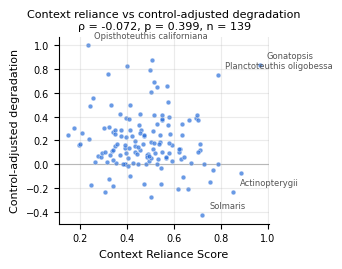

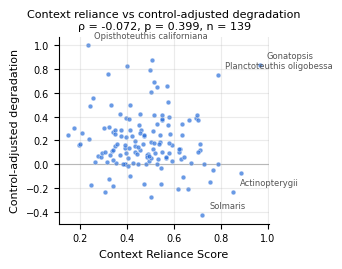

In [28]:
importlib.reload(analysis)
degradation_adj = (per_species_df['degradation'] - per_species_df['control_degradation']).dropna().to_dict()

# How much of the raw degradation ranking survives the adjustment?
r, p = analysis.spearman_correlation(degradation, degradation_adj, species=qualifying)
print(f"raw vs control-adjusted degradation: ρ = {r:.3f}\n")

adj_rows = []
for name, col in [('CRS', 'shallow_crs'), ('excess CRS', 'shallow_crs_excess'),
                  ('predicted-class CRS', 'shallow_crs_pred')]:
    scores = per_species_df[col].dropna().to_dict()
    for subset, sp in [('qualifying', qualifying), ('shallow_acc >= 0.3', learned)]:
        r, p = analysis.spearman_correlation(scores, degradation_adj, species=sp)
        adj_rows.append({'crs': name, 'species': subset, 'n': len(sp), 'rho': r, 'p': p})
adj_corr = pd.DataFrame(adj_rows)

boot_adj = analysis.bootstrap_spearman(image_crs['shallow'], degradation_adj, species=qualifying)
adj_corr.to_csv(os.path.join(config.RESULTS_DIR, 'control_adjusted_correlation.csv'), index=False)
display(adj_corr.round(3))

rho_adj_deg, p_adj_deg = analysis.spearman_correlation(crs_scores, degradation_adj, species=qualifying)
analysis.plot_crs_vs_degradation(crs_scores, degradation_adj, species=qualifying, rho=rho_adj_deg,
                                 p_value=p_adj_deg, ylabel='Control-adjusted degradation',
                                 save_path='results/crs_vs_adjusted_degradation.png')

## Crop-level model: CRS × depth
The species-level tests reduce each species to one degradation value, so a species
with 6 test crops counts as much as one with 600, and every crop's actual depth is
reduced to shallow/deep. Here every test crop is one observation:
`correct ~ depth × crs`, with crs the species' shallow CRS (standardised; never
the crop's own CRS, which the shift itself affects). Crops of one species are not
independent, which is handled two ways: a GEE with standard errors clustered by
species, and a mixed model with a random intercept per species (its own baseline
accuracy). The `depth:crs` coefficient is the test, in log-odds of a correct
prediction per SD of CRS: negative = high-CRS species lose more accuracy at depth.
Fitted with depth as shallow/deep, as continuous km relative to the threshold, and
with the control model's predictions added (`depth:crs:shallow_model`: is the
effect stronger for the shallow-trained model than for the control?).

In [29]:
importlib.reload(analysis)
specs = {
    'deep vs shallow': {},
    'depth (km)': {'depth_df': depth_df, 'depth_threshold': config.DEPTH_SHALLOW_MAX},
    'excess CRS': {'crs_col': 'shallow_crs_excess'},
    'shallow vs control': {'models': ('shallow', 'control')},
}
fits = []
for name, kw in specs.items():
    print(f"\n=== {name} ===")
    fits.append(analysis.crs_depth_model(predictions, per_species_df, species=qualifying, **kw)
                .assign(spec=name))
crs_depth_fits = pd.concat(fits, ignore_index=True)
crs_depth_fits.to_csv(os.path.join(config.RESULTS_DIR, 'crs_depth_model.csv'), index=False)

key_terms = crs_depth_fits[crs_depth_fits['term'].isin(['depth:crs', 'depth:crs:shallow_model'])]
display(key_terms.set_index(['spec', 'method'])[['term', 'coef', 'ci_low', 'ci_high', 'p']].round(3))


=== deep vs shallow ===
correct ~ depth * crs: 23991 crops, 139 species, depth = deep split (0/1), crs = shallow_crs (standardised)
  GEE: depth:crs = 0.317 [-0.158, 0.792], p = 0.19
  Mixed (species intercept): depth:crs = 0.224 [0.166, 0.282], p = 3.6e-14

=== depth (km) ===
correct ~ depth * crs: 23991 crops, 139 species, depth = km relative to 1056 m, crs = shallow_crs (standardised)
  GEE: depth:crs = 0.216 [0.005, 0.427], p = 0.0451
  Mixed (species intercept): depth:crs = 0.171 [0.125, 0.216], p = 1.33e-13

=== excess CRS ===
correct ~ depth * crs: 23991 crops, 139 species, depth = deep split (0/1), crs = shallow_crs_excess (standardised)
  GEE: depth:crs = 0.189 [-0.103, 0.482], p = 0.205
  Mixed (species intercept): depth:crs = 0.146 [0.085, 0.207], p = 2.72e-06

=== shallow vs control ===
correct ~ depth * crs * shallow_model: 47982 crops, 139 species, depth = deep split (0/1), crs = shallow_crs (standardised)
  GEE: depth:crs:shallow_model = 0.055 [-0.201, 0.311], p = 0.674

term   coef  \
spec               method                                                      
deep vs shallow    GEE                                      depth:crs  0.317   
                   Mixed (species intercept)                depth:crs  0.224   
depth (km)         GEE                                      depth:crs  0.216   
                   Mixed (species intercept)                depth:crs  0.171   
excess CRS         GEE                                      depth:crs  0.189   
                   Mixed (species intercept)                depth:crs  0.146   
shallow vs control GEE                                      depth:crs  0.263   
                   GEE                        depth:crs:shallow_model  0.055   
                   Mixed (species intercept)                depth:crs  0.231   
                   Mixed (species intercept)  depth:crs:shallow_model  0.007   

                                              ci_low  ci_high      p  
spec               method                                             
deep vs shallow    GEE                        -0.158    0.792  0.190  
                   Mixed (species intercept)   0.166    0.282  0.000  
depth (km)         GEE                         0.005    0.427  0.045  
                   Mixed (species intercept)   0.125    0.216  0.000  
excess CRS         GEE                        -0.103    0.482  0.205  
                   Mixed (species intercept)   0.085    0.207  0.000  
shallow vs control GEE                        -0.174    0.699  0.238  
                   GEE                        -0.201    0.311  0.674  
                   Mixed (species intercept)   0.188    0.275  0.000  
                   Mixed (species intercept)  -0.050    0.064  0.817

## Background Intervention Results

shallow_acc  deep_acc  degradation  n_species
model   mode                                                             
shallow Original                  0.592     0.440        0.151        139
        Background greyed         0.240     0.201        0.038        139
        Background blurred        0.433     0.337        0.096        139
        Organism greyed           0.066     0.036        0.029        139
control Original                  0.618     0.670       -0.052        139
        Background greyed         0.269     0.304       -0.036        139
        Background blurred        0.500     0.532       -0.033        139
        Organism greyed           0.054     0.048        0.006        139

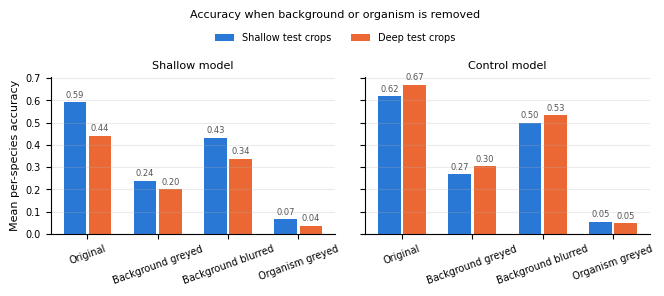

CRS vs accuracy drop (Background greyed): rho = 0.204, p = 0.02, n = 130 species
CRS vs accuracy drop (Background blurred): rho = -0.006, p = 0.942, n = 130 species


In [30]:
importlib.reload(extensions)

int_summary = extensions.intervention_summary(int_preds, species=qualifying)
int_summary.to_csv(os.path.join(config.RESULTS_DIR, 'intervention_summary.csv'))
display(int_summary.round(3))
extensions.plot_intervention_summary(int_summary, save_path='results/intervention_accuracy.png')

# Does greying the background hurt the species Grad-CAM said rely on it?
bg_dep, bg_dep_stats = extensions.background_dependence(int_preds, crs_scores, species=qualifying)




In [31]:
boot = extensions.bootstrap_intervention(int_preds, species=qualifying)
boot.to_csv(os.path.join(config.RESULTS_DIR, 'intervention_bootstrap.csv'), index=False)
display(boot.round(3))


Bootstrap over 139 species, 2000 resamples


,model,mode,metric,estimate,ci_low,ci_high,significant
0,shallow,Background greyed,degradation,0.038,0.015,0.063,True
1,shallow,Background greyed,reduction,0.113,0.076,0.151,True
2,shallow,Background greyed,retention_gap,0.052,0.003,0.104,True
3,control,Background greyed,degradation,-0.036,-0.069,-0.003,True
4,control,Background greyed,reduction,-0.017,-0.054,0.022,False
5,control,Background greyed,retention_gap,0.019,-0.026,0.064,False
6,shallow - control,Background greyed,retention_gap,0.033,-0.021,0.092,False
7,shallow,Background blurred,degradation,0.096,0.066,0.127,True
8,shallow,Background blurred,reduction,0.055,0.026,0.084,True
9,shallow,Background blurred,retention_gap,0.033,-0.018,0.083,False


### Background Swap

Swap decomposition over 139 species, 2000 resamples


,model,metric,estimate,ci_low,ci_high,significant
0,shallow,original_degradation,0.151,0.112,0.190,True
1,shallow,composite_degradation,0.044,0.019,0.068,True
2,shallow,background_effect,-0.007,-0.017,0.003,False
3,shallow,organism_effect,0.051,0.028,0.074,True
4,shallow,compositing_cost,0.292,0.256,0.327,True
5,shallow,background_share,-0.164,-0.696,0.055,False
6,control,original_degradation,-0.052,-0.094,-0.013,True
7,control,composite_degradation,-0.023,-0.055,0.007,False
8,control,background_effect,-0.001,-0.014,0.010,False
9,control,organism_effect,-0.022,-0.049,0.004,False


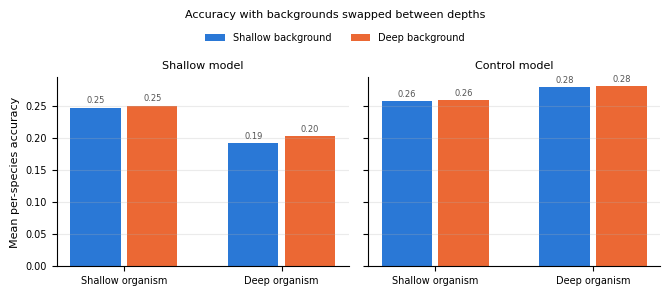

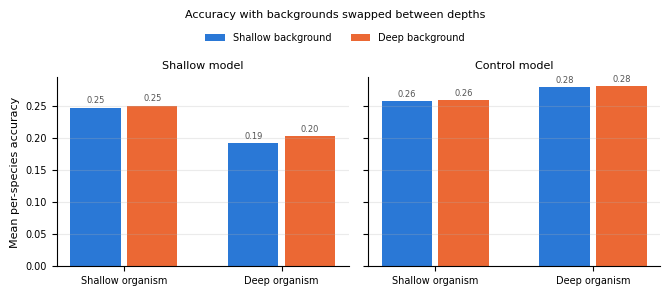

In [32]:
# Background swap: how much of the degradation follows the background vs the organism?
importlib.reload(extensions)
swap_preds = pd.read_csv(os.path.join(config.RESULTS_DIR, 'swap_predictions.csv'))

swap = extensions.swap_decomposition(swap_preds, species=qualifying)
swap.to_csv(os.path.join(config.RESULTS_DIR, 'swap_decomposition.csv'), index=False)
display(swap.round(3))

extensions.plot_swap(swap_preds, species=qualifying, save_path='results/background_swap.png')

### Within-species CRS variance vs degradation
The image-level analysis shows CRS predicts errors within species, but species-level mean CRS doesn't predict degradation. Does CRS *variance* bridge that gap? Species with inconsistent context reliance (high variance) may be more vulnerable to distribution shift than species with stable CRS.

CRS std vs degradation: rho = -0.204, p = 0.0161, n = 138 species
CRS iqr vs degradation: rho = -0.114, p = 0.184, n = 138 species
CRS mean vs degradation: rho = -0.189, p = 0.026, n = 138 species


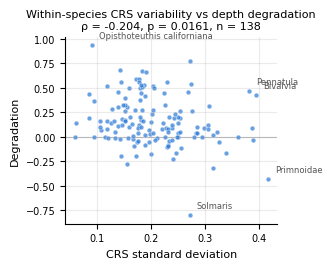

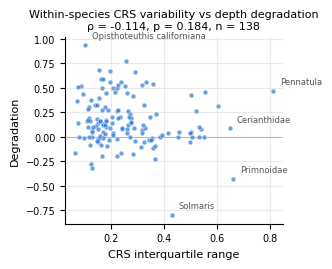

,mean,std,iqr,count,degradation
count,138.000,138.000,138.000,138.000,138.000
mean,0.476,0.204,0.254,97.935,0.161
std,0.148,0.071,0.141,155.308,0.251
min,0.149,0.059,0.064,5.000,-0.800
25%,0.371,0.154,0.153,13.000,0.000
50%,0.473,0.190,0.217,29.000,0.123
75%,0.569,0.247,0.319,111.500,0.303
max,0.886,0.416,0.813,755.000,0.933


In [33]:
importlib.reload(extensions)

# Per-species CRS std, IQR, and mean vs degradation (shallow image CRS)
var_df, var_stats = extensions.crs_variance_analysis(
    image_crs['shallow'], degradation, species=qualifying)

# Scatter plot for CRS std
rho_std, p_std, n_std = var_stats['std']
extensions.plot_crs_variance_vs_degradation(
    var_df, metric='std', rho=rho_std, p_value=p_std,
    save_path='results/crs_variance_vs_degradation.png')

# Also show IQR (more robust to outliers)
rho_iqr, p_iqr, n_iqr = var_stats['iqr']
extensions.plot_crs_variance_vs_degradation(
    var_df, metric='iqr', rho=rho_iqr, p_value=p_iqr)

display(var_df[['mean', 'std', 'iqr', 'count', 'degradation']].describe().round(3))

### CRS adjusted for mask size
CRS measures the fraction of Grad-CAM activation outside the (dilated) organism mask.
Species with smaller masks will mechanically score higher even if the model
focuses on the organism, because more area lies outside the mask.

Each crop's chance CRS is what a flat heatmap would score on its mask, i.e.
1 − organism coverage (`crs_chance`; the species mean equals `uniform_crs`).
Three ways to remove the geometric effect:
- **Excess CRS** = CRS − chance, averaged per species. 0 means no more
  context-reliant than chance; above 0 means more. It is capped at the
  coverage, so very small organisms can't score highly.
- **Partial Spearman** of CRS vs degradation, controlling for coverage.
- **OLS** `degradation ~ crs + mask_coverage` (standardised predictors).

Mask coverage vs CRS: ρ = -0.592, p = 1.62e-14, n = 139
Raw CRS vs degradation: ρ = -0.199, p = 0.0191, n = 139
Excess CRS vs degradation: ρ = -0.211, p = 0.0127, n = 139
CRS vs degradation, controlling for coverage: partial ρ = -0.142, p = 0.097, n = 139
OLS degradation ~ crs + coverage: crs coef = -0.066 (p = 0.0104), coverage coef = -0.018 (p = 0.474)


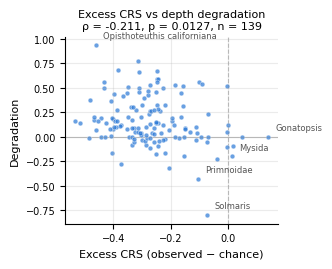

,crs,mask_coverage,crs_excess,degradation
count,139.000,139.000,139.000,139.000
mean,0.479,0.252,-0.269,0.160
std,0.154,0.073,0.127,0.251
min,0.149,0.091,-0.534,-0.800
25%,0.371,0.193,-0.350,0.000
50%,0.473,0.250,-0.276,0.121
75%,0.571,0.293,-0.201,0.302
max,0.967,0.594,0.139,0.933


In [34]:
importlib.reload(extensions)

adj_df, adj_stats, adj_fit = extensions.crs_mask_size_analysis(per_species_df, species=qualifying)

# Scatter: excess CRS vs degradation
rho_adj, p_adj, n_adj = adj_stats['excess_crs_vs_degradation']
extensions.plot_excess_crs_vs_degradation(
    adj_df, rho=rho_adj, p_value=p_adj,
    save_path='results/excess_crs_vs_degradation.png')

display(adj_df[['crs', 'mask_coverage', 'crs_excess', 'degradation']].describe().round(3))

### Is degradation driven by context reliance?
For species whose accuracy degrades at depth, is this because they relied on
background context in shallow water? If so, removing the background should
shrink the shallow-to-deep accuracy gap for degrading species more than for
non-degrading ones.

Background reliance vs degradation: ρ = -0.048, p = 0.589, n = 130
Degradation reduction vs degradation: ρ = 0.570, p = 2.45e-13, n = 139
Background reliance vs degradation: ρ = 0.004, p = 0.963, n = 130
Degradation reduction vs degradation: ρ = 0.365, p = 9.73e-06, n = 139


/content/drive/Shareddrives/CV-Project/extensions.py:844: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return fig
/content/drive/Shareddrives/CV-Project/extensions.py:845: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  
/content/drive/Shareddrives/CV-Project/extensions.py:844: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return fig
/content/drive/Shareddrives/CV-Project/extensions.py:845: FutureWarning: The default of o

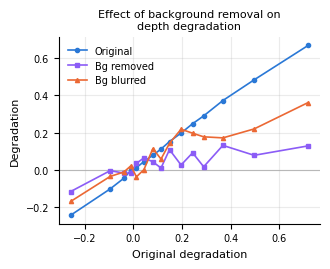

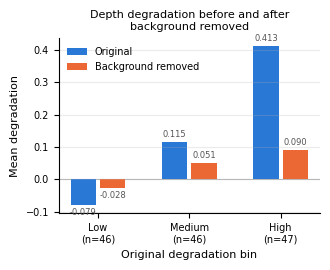

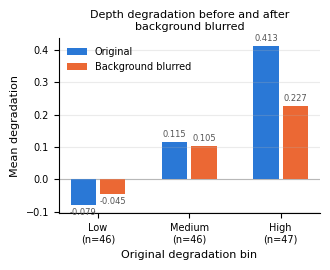


--- Control model ---
Background reliance vs degradation: ρ = -0.075, p = 0.401, n = 129
Degradation reduction vs degradation: ρ = 0.227, p = 0.00733, n = 139
Background reliance vs degradation: ρ = 0.064, p = 0.469, n = 129
Degradation reduction vs degradation: ρ = 0.146, p = 0.0861, n = 139


/content/drive/Shareddrives/CV-Project/extensions.py:844: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return fig
/content/drive/Shareddrives/CV-Project/extensions.py:845: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  
/content/drive/Shareddrives/CV-Project/extensions.py:844: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return fig
/content/drive/Shareddrives/CV-Project/extensions.py:845: FutureWarning: The default of o

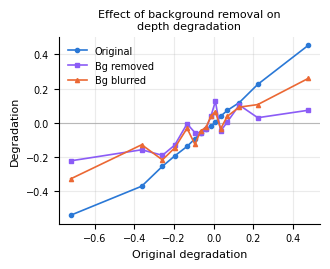

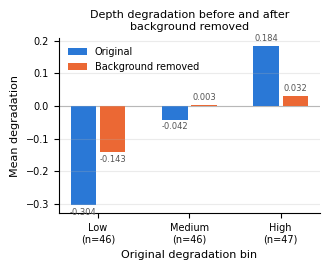

/content/drive/Shareddrives/CV-Project/analysis.py:279: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  def generate_summary_table(crs_scores, degradation_scores, rho, p_value,
/content/drive/Shareddrives/CV-Project/analysis.py:279: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  def generate_summary_table(crs_scores, degradation_scores, rho, p_value,
/content/drive/Shareddrives/CV-Project/analysis.py:279: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default 

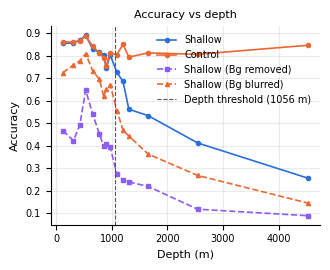

/content/drive/Shareddrives/CV-Project/analysis.py:280: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  baselines=None, species=None):
/content/drive/Shareddrives/CV-Project/analysis.py:281: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  """Create a summary DataFrame with per-species CRS, degradation,
/content/drive/Shareddrives/CV-Project/analysis.py:280: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  baselines=None, specie

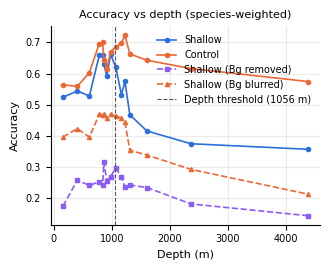

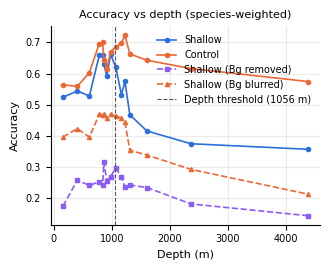

In [35]:
importlib.reload(extensions)
importlib.reload(analysis)


# Shallow model — per-species degradation before and after interventions
ctx_df_grey, _ = extensions.degradation_context_analysis(
    int_preds, degradation, species=qualifying, model='shallow', mode='grey_bg')
ctx_df_blur, _ = extensions.degradation_context_analysis(
    int_preds, degradation, species=qualifying, model='shallow', mode='blur_bg')


# Continuous line plot — shallow model
extensions.plot_degradation_before_after(
    ctx_df_grey, df_blur=ctx_df_blur,
    save_path='results/degradation_before_after.png')

# Binned bar charts
extensions.plot_degradation_bar(
    ctx_df_grey, mode_label='background removed',
    save_path='results/degradation_bar_grey.png')

extensions.plot_degradation_bar(
    ctx_df_blur, mode_label='background blurred',
    save_path='results/degradation_bar_blur.png')

# --- Control model (negative control for regression to the mean) ---
print('\n--- Control model ---')
ctrl_df_grey, _ = extensions.degradation_context_analysis(
    int_preds, degradation, species=qualifying, model='control', mode='grey_bg')
ctrl_df_blur, _ = extensions.degradation_context_analysis(
    int_preds, degradation, species=qualifying, model='control', mode='blur_bg')

extensions.plot_degradation_before_after(
    ctrl_df_grey, df_blur=ctrl_df_blur,
    save_path='results/degradation_before_after_control.png')

extensions.plot_degradation_bar(
    ctrl_df_grey, mode_label='background removed',
    save_path='results/degradation_bar_grey_control.png')

# Accuracy vs depth

analysis.plot_accuracy_vs_depth(
    predictions, depth_df,
    depth_threshold=config.DEPTH_SHALLOW_MAX,
    int_preds=int_preds, int_modes=['grey_bg', 'blur_bg'],
    save_path='results/accuracy_vs_depth_bgintervention.png')

# Species-weighted accuracy vs depth — every species counts equally

# Filter to qualifying species for fair species-weighted comparison
qual_preds = predictions[predictions['species'].isin(qualifying)]
qual_int = int_preds[int_preds['species'].isin(qualifying)]

analysis.plot_accuracy_vs_depth(
    qual_preds, depth_df,
    depth_threshold=config.DEPTH_SHALLOW_MAX,
    int_preds=qual_int, int_modes=['grey_bg', 'blur_bg'],
    species_weighted=True,
    save_path='results/accuracy_vs_depth_species_weighted.png')

### High-degradation species
The overall Spearman looks for one trend across every species, so background
reliance that drives degradation in only some species gets diluted. Here the top
quartile of degradation (fixed in advance; other cutoffs are a sensitivity check
only) is compared with the rest on CRS and background reliance, and quantile
regression tests whether the upper tail of degradation rises with excess CRS.
A species can only degrade as far as its shallow accuracy, so the test is
repeated on relative degradation (degradation / shallow accuracy), and
`shallow_acc` is shown per group as a check.

In [36]:
importlib.reload(extensions)
hd_df = per_species_df.join(ctx_df_grey['bg_reliance'])
hd_df['relative_degradation'] = hd_df['degradation'] / hd_df['shallow_acc'].where(hd_df['shallow_acc'] > 0)

for deg_col in ['degradation', 'relative_degradation']:
    tbl = extensions.high_degradation_test(hd_df, species=qualifying, deg_col=deg_col)
    tbl.to_csv(os.path.join(config.RESULTS_DIR, f'high_{deg_col}_test.csv'))
    display(tbl.round(3))

# Sensitivity to the cutoff (report, don't pick from)
for q in [0.67, 0.9]:
    t = extensions.high_degradation_test(hd_df, species=qualifying, quantile=q)
    print(t.loc[['shallow_crs_excess', 'bg_reliance'], ['diff', 'p']].round(3))

High degradation: >= 0.302 (35 of 139 species)


,high_mean,rest_mean,diff,p,n_high,n_rest
shallow_crs,0.459,0.486,-0.028,0.626,35.0,104.0
shallow_crs_excess,-0.282,-0.264,-0.017,0.640,35.0,104.0
shallow_crs_pred_excess,-0.297,-0.312,0.015,0.430,35.0,104.0
bg_reliance,0.692,0.592,0.100,0.304,34.0,96.0
shallow_acc,0.750,0.549,0.201,0.002,35.0,104.0


High relative_degradation: >= 0.575 (33 of 131 species)


,high_mean,rest_mean,diff,p,n_high,n_rest
shallow_crs,0.491,0.458,0.033,0.159,33.0,98.0
shallow_crs_excess,-0.247,-0.290,0.044,0.043,33.0,98.0
shallow_crs_pred_excess,-0.293,-0.319,0.026,0.144,33.0,98.0
bg_reliance,0.616,0.613,0.003,0.358,30.0,96.0
shallow_acc,0.545,0.667,-0.121,0.028,33.0,98.0


High degradation: >= 0.203 (46 of 139 species)
                     diff      p
shallow_crs_excess -0.016  0.725
bg_reliance         0.100  0.359
High degradation: >= 0.520 (14 of 139 species)
                     diff      p
shallow_crs_excess  0.005  0.622
bg_reliance         0.195  0.082


In [37]:
# Tail test: does the upper end of degradation rise with excess CRS, even if the middle doesn't?
import statsmodels.formula.api as smf
qr_df = hd_df.loc[qualifying, ['degradation', 'shallow_crs_excess']].dropna()
for q in [0.5, 0.75, 0.9]:
    fit = smf.quantreg('degradation ~ shallow_crs_excess', qr_df).fit(q=q)
    lo, hi = fit.conf_int().loc['shallow_crs_excess']
    print(f"quantile {q}: slope = {fit.params['shallow_crs_excess']:.3f} "
          f"[{lo:.3f}, {hi:.3f}], p = {fit.pvalues['shallow_crs_excess']:.3g}")

quantile 0.5: slope = -0.296 [-0.651, 0.060], p = 0.102
quantile 0.75: slope = -0.379 [-0.955, 0.197], p = 0.196
quantile 0.9: slope = 0.086 [-0.490, 0.663], p = 0.768


## Sensitivity check: same-species masks
Everything above uses the target annotation alone as the organism, so another
individual of the same species in the crop counts as context. Here CRS is
recomputed (train notebook, last section) with every annotation of the
target's species in the crop counted as organism — the pointing-game
convention (Zhang et al. 2016), and a better match for Grad-CAM, which
highlights every individual of the explained class. Only crops with another
annotated individual of the species (`extra_organisms`) can change.

If the conclusions above hold under both mask definitions, they aren't an
artefact of how neighbouring individuals are labelled.

shallow: 14.8% of 13551 qualifying-species test crops contain another individual of the same species
deep: 13.1% of 10440 qualifying-species test crops contain another individual of the same species
Spearman ρ between the two species CRS rankings: 0.980 (n = 139)


,crs_target,crs_same_species,change
count,139.000,139.000,139.000
mean,0.479,0.469,-0.011
std,0.154,0.156,0.027
min,0.149,0.149,-0.169
25%,0.371,0.358,-0.008
50%,0.473,0.455,-0.000
75%,0.571,0.571,0.000
max,0.967,0.967,0.000


,crs_target,crs_same_species,change
species,,,
Marrus orthocanna,0.548,0.379,-0.169
Bathochordaeus mcnutti,0.395,0.238,-0.158
Vesicomya,0.702,0.578,-0.124
Vesicomyidae,0.532,0.429,-0.103
Kephyes ovata,0.410,0.324,-0.086
Marrus claudanielis,0.486,0.404,-0.082
Apolemia,0.513,0.447,-0.066
Isosicyonis,0.340,0.285,-0.055
Tottonophyes enigmatica,0.320,0.270,-0.050


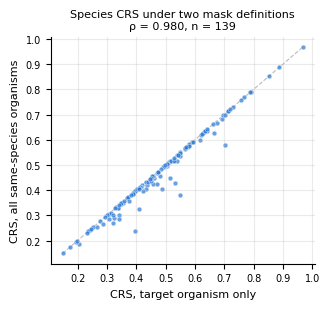

In [38]:
import matplotlib.pyplot as plt

crs_sp = pd.read_csv(os.path.join(config.RESULTS_DIR, 'crs_same_species.csv'), index_col='species')
all_ic_sp = pd.read_csv(os.path.join(config.RESULTS_DIR, 'image_crs_same_species.csv'))
image_crs_sp = {s: all_ic_sp[all_ic_sp['split'] == s].drop(columns='split') for s in ['shallow', 'deep']}

# How many crops does the mask definition affect?
for s, ic in image_crs_sp.items():
    q = ic[ic['species'].isin(qualifying)]
    print(f"{s}: {q['extra_organisms'].mean():.1%} of {len(q)} qualifying-species test crops "
          f"contain another individual of the same species")

# Per-species CRS under the two definitions
mask_cmp = pd.DataFrame({'crs_target': per_species_df['shallow_crs'].reindex(qualifying),
                         'crs_same_species': crs_sp['shallow_crs'].reindex(qualifying)}).dropna()
mask_cmp['change'] = mask_cmp['crs_same_species'] - mask_cmp['crs_target']
rho_cmp = mask_cmp['crs_target'].corr(mask_cmp['crs_same_species'], method='spearman')
print(f"Spearman ρ between the two species CRS rankings: {rho_cmp:.3f} (n = {len(mask_cmp)})")
display(mask_cmp.describe().round(3))
display(mask_cmp.sort_values('change').head(10).round(3))   # species whose CRS drops most

fig, ax = plt.subplots(figsize=(3.4, 3.2))
lo, hi = mask_cmp[['crs_target', 'crs_same_species']].min().min(), mask_cmp[['crs_target', 'crs_same_species']].max().max()
ax.plot([lo, hi], [lo, hi], color='#bbbbbb', linewidth=0.8, linestyle='--', zorder=0)
ax.scatter(mask_cmp['crs_target'], mask_cmp['crs_same_species'], s=12, color='#2a78d6', alpha=0.7,
           edgecolor='white', linewidth=0.4)
ax.set_xlabel('CRS, target organism only', fontsize=8)
ax.set_ylabel('CRS, all same-species organisms', fontsize=8)
ax.set_title(f'Species CRS under two mask definitions\nρ = {rho_cmp:.3f}, n = {len(mask_cmp)}', fontsize=8, pad=6)
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(labelsize=7)
ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig('results/crs_target_vs_same_species.png', dpi=300, bbox_inches='tight')
plt.show()

In [39]:
importlib.reload(extensions)
importlib.reload(analysis)

# Re-run the main CRS tests under both mask definitions, side by side
versions = {
    'target only': (per_species_df, image_crs),
    'same species': (crs_sp.join(per_species_df['degradation']), image_crs_sp),
}
learned = [s for s in qualifying if shallow_acc[s] >= 0.3]

rows = {}
for name, (sp_df, ic) in versions.items():
    print(f"\n=== {name} ===")
    scores = sp_df['shallow_crs'].dropna().to_dict()
    rho, p = analysis.spearman_correlation(scores, degradation, species=qualifying)
    rho_l, p_l = analysis.spearman_correlation(scores, degradation, species=learned)
    _, adj, _ = extensions.crs_mask_size_analysis(sp_df, species=qualifying)
    _, var = extensions.crs_variance_analysis(ic['shallow'], degradation, species=qualifying)
    cw = {s: extensions.crs_correct_vs_incorrect(ic[s], species=qualifying, label=f'{name}, {s}')
          for s in ['shallow', 'deep']}
    row = {'mean species CRS': sp_df['shallow_crs'].reindex(qualifying).mean(),
           'ρ CRS vs degradation': rho, 'p': p,
           'ρ CRS vs degradation (shallow_acc ≥ 0.3)': rho_l, 'p (shallow_acc ≥ 0.3)': p_l,
           'ρ excess CRS vs degradation': adj['excess_crs_vs_degradation'][0],
           'p excess': adj['excess_crs_vs_degradation'][1],
           'partial ρ CRS vs degradation (coverage)': adj['partial_crs_vs_degradation'][0],
           'p partial': adj['partial_crs_vs_degradation'][1],
           'ρ CRS std vs degradation': var['std'][0], 'p std': var['std'][1]}
    for s in cw:
        row[f'within-species CRS diff, wrong − right ({s})'] = cw[s]['median_within_species_diff']
        row[f'p within-species ({s})'] = cw[s]['p_within']
    rows[name] = row

mask_def_comparison = pd.DataFrame(rows)
mask_def_comparison.to_csv(os.path.join(config.RESULTS_DIR, 'crs_mask_definition_comparison.csv'))
display(mask_def_comparison.round(4))


=== target only ===
Spearman over 139 species
Spearman over 111 species
Mask coverage vs CRS: ρ = -0.592, p = 1.62e-14, n = 139
Raw CRS vs degradation: ρ = -0.199, p = 0.0191, n = 139
Excess CRS vs degradation: ρ = -0.211, p = 0.0127, n = 139
CRS vs degradation, controlling for coverage: partial ρ = -0.142, p = 0.097, n = 139
OLS degradation ~ crs + coverage: crs coef = -0.066 (p = 0.0104), coverage coef = -0.018 (p = 0.474)
CRS std vs degradation: rho = -0.204, p = 0.0161, n = 138 species
CRS iqr vs degradation: rho = -0.114, p = 0.184, n = 138 species
CRS mean vs degradation: rho = -0.189, p = 0.026, n = 138 species
[target only, shallow] median CRS correct 0.376 vs incorrect 0.501 (pooled p = 5.56e-101); within 101 species, median diff = 0.098 (p = 4.25e-15); empty maps left out: 0 correct, 32 wrong
[target only, deep] median CRS correct 0.434 vs incorrect 0.594 (pooled p = 2.98e-125); within 100 species, median diff = 0.130 (p = 5.05e-15); empty maps left out: 0 correct, 85 wrong


,target only,same species
mean species CRS,0.4793,0.4686
ρ CRS vs degradation,-0.1986,-0.2320
p,0.0191,0.0060
ρ CRS vs degradation (shallow_acc ≥ 0.3),-0.0314,-0.0765
p (shallow_acc ≥ 0.3),0.7434,0.4248
ρ excess CRS vs degradation,-0.2108,-0.2169
p excess,0.0127,0.0103
partial ρ CRS vs degradation (coverage),-0.1418,-0.1650
p partial,0.0970,0.0532
ρ CRS std vs degradation,-0.2045,-0.2121
